# PR 5 — Sentiment Analysis with RNN, LSTM and GRU
**Red & White Skill Education | Deep Learning**

**Objective:** Build and compare an order-blind ANN baseline, SimpleRNN, LSTM, and GRU for binary IMDB review sentiment classification.

**Dataset required:** `IMDB Dataset.csv` from [Kaggle — IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews)

> Put the CSV beside this notebook. This notebook is organized to cover the seven tasks in the supplied PR 5 specification. Training experiments can take substantial time and GPU memory. Run from top to bottom.

In [4]:
import os, re, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, SimpleRNN, LSTM, GRU, RepeatVector
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.callbacks import EarlyStopping, Callback
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             roc_curve)
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme()
os.makedirs("plots", exist_ok=True)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## Task 1: Load, clean, tokenize and pad the text
**Objective:** Inspect and clean the raw reviews, remove duplicates, analyse review lengths, split the data before fitting the tokenizer, and create padded sequences.
**Output:** Dataset inspection, length plots, tokenizer examples, and train/test shapes.

In [5]:
DATA_PATH = "IMDB Dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\nSentiment counts:")
print(df["sentiment"].value_counts())
print("\nMissing values:")
print(df.isnull().sum())
print("\nTwo raw reviews:")
print(df.loc[0, "review"])
print("\n--- Review 2 ---\n")
print(df.loc[1, "review"])

Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Sentiment counts:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Missing values:
review       0
sentiment    0
dtype: int64

Two raw reviews:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, 

### 1.2 Remove duplicates
Duplicates must be removed **before** splitting; otherwise the same review could occur in training and test sets, causing data leakage and overly optimistic test metrics.

In [6]:
rows_before = len(df)
duplicate_count = int(df.duplicated(subset=["review", "sentiment"]).sum())
df = df.drop_duplicates(subset=["review", "sentiment"]).reset_index(drop=True)
print("Rows before:", rows_before)
print("Exact duplicate rows:", duplicate_count)
print("Rows after:", len(df))
df = df.dropna(subset=["review", "sentiment"]).copy()

Rows before: 50000
Exact duplicate rows: 418
Rows after: 49582


### 1.3 Clean text
Apostrophes are retained because contractions such as `don't` and `can't` carry meaning. Stop words are not removed because words such as **not** and **no**, and the order of words, can change sentiment.

In [7]:
def clean_text(s):
    s = str(s).lower()
    s = re.sub(r"<.*?>", " ", s)
    s = re.sub(r"[^a-z']", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

In [8]:
print("Before:", df.loc[0, "review"][:500])
df["clean_review"] = df["review"].apply(clean_text)
print("\nAfter:", df.loc[0, "clean_review"][:500])
df["sentiment"] = df["sentiment"].str.lower().str.strip()
df = df[df["sentiment"].isin(["positive", "negative"])].reset_index(drop=True)
y = df["sentiment"].map({"negative": 0, "positive": 1}).astype("int32")
texts = df["clean_review"].astype(str)

Before: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

After: one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its brutality and unflinching scenes of violence which set in right from the word go trust me this is not a show for the faint hearted or timid this show pulls no punches with regards to drugs sex or violence its is hardcore in the classic use of the word it is called oz as that is the ni

### 1.4 Review length analysis
The length distribution is typically right-skewed: a small number of reviews are much longer than most. `MAXLEN` is selected from the 95th percentile, rounded to a practical multiple of 10, and capped to keep training manageable.

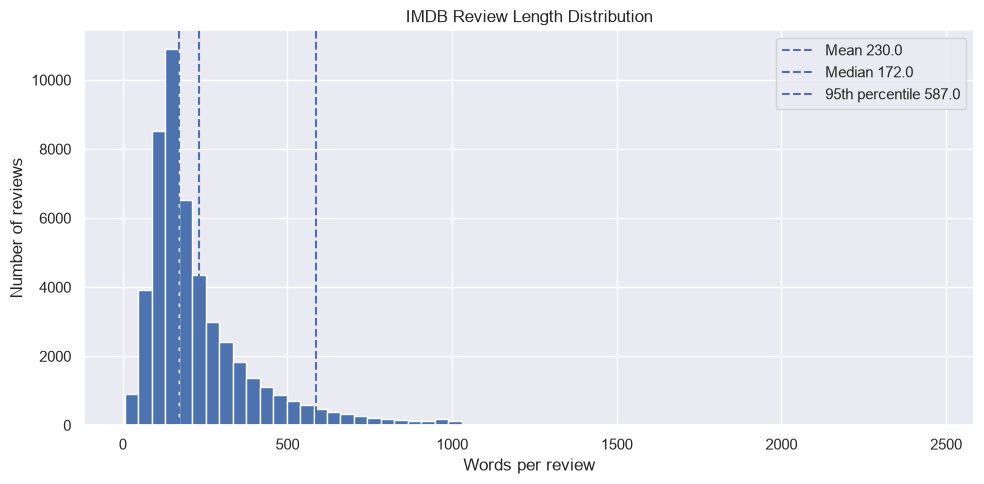

In [9]:
df["word_count"] = texts.str.split().str.len()
mean_len = df["word_count"].mean()
median_len = df["word_count"].median()
p95_len = df["word_count"].quantile(0.95)
plt.figure(figsize=(10, 5))
plt.hist(df["word_count"], bins=60)
plt.axvline(mean_len, linestyle="--", label=f"Mean {mean_len:.1f}")
plt.axvline(median_len, linestyle="--", label=f"Median {median_len:.1f}")
plt.axvline(p95_len, linestyle="--", label=f"95th percentile {p95_len:.1f}")
plt.title("IMDB Review Length Distribution")
plt.xlabel("Words per review"); plt.ylabel("Number of reviews"); plt.legend()
plt.tight_layout(); plt.savefig("plots/review_length_histogram.png", dpi=150); plt.show()

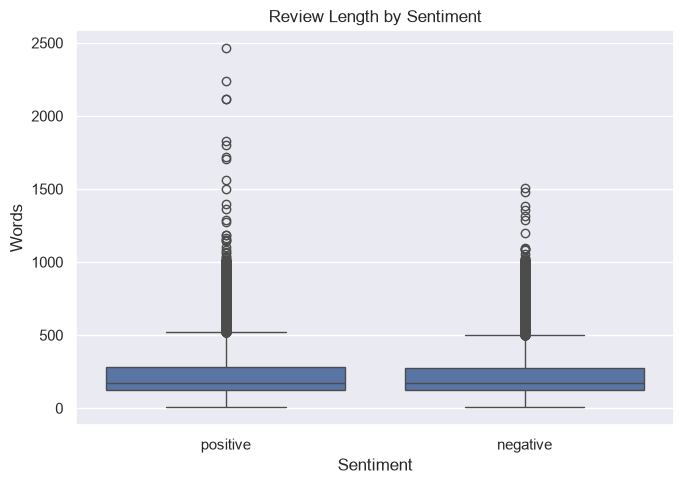

In [10]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="sentiment", y="word_count")
plt.title("Review Length by Sentiment"); plt.xlabel("Sentiment"); plt.ylabel("Words")
plt.tight_layout(); plt.savefig("plots/review_length_by_sentiment.png", dpi=150); plt.show()

In [11]:
MAXLEN = int(np.clip(np.ceil(p95_len / 10) * 10, 50, 300))
print(f"Mean={mean_len:.1f}, median={median_len:.1f}, p95={p95_len:.1f}; chosen MAXLEN={MAXLEN}")

Mean=230.0, median=172.0, p95=587.0; chosen MAXLEN=300


### 1.5–1.6 Split first, fit tokenizer on training texts only, then pad
The vocabulary is limited to 10,000 words to reduce rare-word noise and model size. The OOV token represents words not in the retained vocabulary. Pre-padding places real words at the end, matching the final hidden-state reading used by these models.

In [12]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    texts, y, test_size=0.2, random_state=42, stratify=y
)
VOCAB_SIZE = 10000
EMBEDDING_DIM = 32
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)
train_seq = tokenizer.texts_to_sequences(X_train_text)
test_seq = tokenizer.texts_to_sequences(X_test_text)
X_train = pad_sequences(train_seq, maxlen=MAXLEN, padding="pre", truncating="pre")
X_test = pad_sequences(test_seq, maxlen=MAXLEN, padding="pre", truncating="pre")
y_train = np.asarray(y_train, dtype="int32")
y_test = np.asarray(y_test, dtype="int32")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)
print("10 frequent words:", list(tokenizer.word_index.items())[:10])
print("Example integer sequence:", train_seq[0][:40])

X_train: (39665, 300) y_train: (39665,)
X_test: (9917, 300) y_test: (9917,)
10 frequent words: [('<OOV>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('in', 8), ('it', 9), ('i', 10)]
Example integer sequence: [10, 234, 27, 5, 1, 4935, 3, 10, 81, 158, 8, 32, 1, 454, 2767, 7929, 121, 2, 151, 10, 25, 105, 83, 705, 35, 1, 3781, 6, 547, 1, 25, 6453, 1909, 1, 20, 547, 1417, 1, 3, 25]


### 1.7 Why this is sequential data
The meaning of a review depends on word order and context. “The movie was not good” differs from “The movie was good, not bad.” A bag-of-words model ignores order; recurrent models process tokens in sequence.

## Task 2: RNN basics and ANN baseline
**Objective:** Establish an order-blind ANN baseline, explain recurrent state and verify a hand-computed RNN against Keras.
**Output:** Baseline metrics, NumPy hidden states and a heatmap, Keras equivalence check, and ANN/RNN comparison.

In [13]:
def build_ann_baseline(maxlen=MAXLEN):
    model = Sequential([
        Input(shape=(maxlen,)),
        Embedding(VOCAB_SIZE, EMBEDDING_DIM),
        Flatten(),
        Dense(64, activation="relu"),
        Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

In [14]:
ann_model = build_ann_baseline()
ann_model.summary()
ann_start = time.time()
ann_history = ann_model.fit(X_train, y_train, epochs=5, batch_size=64,
                            validation_split=0.1, verbose=1)
ann_train_seconds = time.time() - ann_start
ann_prob = ann_model.predict(X_test, verbose=0).ravel()
ann_pred = (ann_prob >= 0.5).astype(int)
ann_auc = roc_auc_score(y_test, ann_prob)
print("ANN test accuracy:", accuracy_score(y_test, ann_pred))
print("ANN parameters:", ann_model.count_params(), "training seconds:", round(ann_train_seconds, 2))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       614,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 934,529 (3.56 MB)

 Trainable params: 934,529 (3.56 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8068 - loss: 0.3947 - val_accuracy: 0.8757 - val_loss: 0.3004
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9419 - loss: 0.1565 - val_accuracy: 0.8535 - val_loss: 0.3937
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9845 - loss: 0.0482 - val_accuracy: 0.8389 - val_loss: 0.5586
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9949 - loss: 0.0166 - val_accuracy: 0.8326 - val_loss: 0.6947
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9976 - loss: 0.0085 - val_accuracy: 0.8193 - val_loss: 0.8369
ANN test accuracy: 0.8332156902288999
ANN parameters: 934529 training seconds: 27.91


### RNN intuition
An RNN reads one token at a time and carries a hidden state summarizing previous tokens. Its weights are reused at every time step.

\[
h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1}+b),\qquad
y_t=f(W_{hy}h_t+b_y)
\]

`x_t` is the current input, `h_(t-1)` the previous state, `W_xh` input weights, `W_hh` recurrent weights, and `b` the bias. Weight sharing keeps parameter count independent of sequence length.

Manual hidden states:
 [[-3.87642276e-01 -9.54131773e-01  4.04291498e-01]
 [-5.84081354e-01 -1.79948778e-01  4.84723564e-01]
 [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
 [-8.65741745e-01 -5.08259630e-01  7.75117496e-01]]


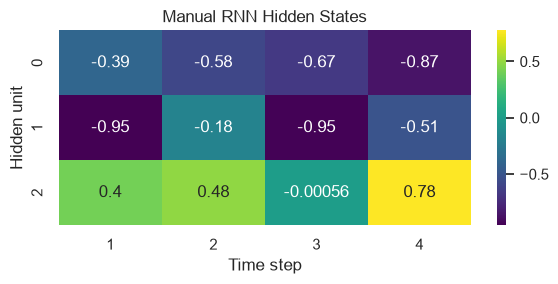

In [15]:
np.random.seed(42)
input_size, hidden_size, steps = 2, 3, 4
Wxh = np.random.randn(hidden_size, input_size) * 0.5
Whh = np.random.randn(hidden_size, hidden_size) * 0.5
b = np.random.randn(hidden_size) * 0.5
x_seq = np.random.randn(steps, input_size)
h = np.zeros(hidden_size)
manual_states = []
for t in range(steps):
    h = np.tanh(Wxh @ x_seq[t] + Whh @ h + b)
    manual_states.append(h.copy())
manual_states = np.asarray(manual_states)
print("Manual hidden states:\n", manual_states)
plt.figure(figsize=(6, 3))
sns.heatmap(manual_states.T, annot=True, cmap="viridis", xticklabels=range(1, steps+1))
plt.title("Manual RNN Hidden States"); plt.xlabel("Time step"); plt.ylabel("Hidden unit")
plt.tight_layout(); plt.savefig("plots/manual_rnn_heatmap.png", dpi=150); plt.show()

In [16]:
verify_rnn = Sequential([Input(shape=(steps, input_size)),
                         SimpleRNN(hidden_size, return_sequences=True, use_bias=True)])
_ = verify_rnn(np.zeros((1, steps, input_size), dtype="float32"))
verify_rnn.layers[-1].set_weights([Wxh.T, Whh.T, b])
keras_states = verify_rnn.predict(x_seq[np.newaxis, ...].astype("float32"), verbose=0)[0]
print("Keras matches NumPy:", np.allclose(manual_states, keras_states, atol=1e-6))
print("SimpleRNN(64) params on embedding 32:", 64 * (32 + 64 + 1))

Keras matches NumPy: True
SimpleRNN(64) params on embedding 32: 6208


### ANN vs RNN
| Property | ANN baseline | RNN |
|---|---|---|
| Input handling | Fixed position slots | Sequential time steps |
| Word order | Position-sensitive but not shared sequence reasoning | Naturally models order |
| Weight sharing | No recurrent sharing | Same recurrent weights at each step |
| Parameters vs length | Flattened head grows with `MAXLEN` | Recurrent cell count independent of `MAXLEN` |
| Memory | No explicit recurrent state | Hidden state carries prior context |
| Typical use | Tabular/fixed-vector data | Text, speech, time series |

## Task 3: RNN types and SimpleRNN model
**Objective:** Demonstrate four sequence mappings and train/evaluate a many-to-one SimpleRNN classifier.
**Output:** Shape table, learning curves, classification metrics, confusion matrix and embedding examples.

In [17]:
dummy = tf.zeros((4, 10, 8))
one_to_one = Dense(1)(dummy[:, 0, :])
one_to_many = Sequential([Input(shape=(8,)), RepeatVector(10),
                          SimpleRNN(16, return_sequences=True)])(tf.zeros((4, 8)))
many_to_one = SimpleRNN(16)(dummy)
many_to_many = SimpleRNN(16, return_sequences=True)(dummy)
shape_table = pd.DataFrame([
    ["One-to-one", "(4, 8)", str(tuple(one_to_one.shape)), "N/A", "Fixed-vector classification"],
    ["One-to-many", "(4, 8)", str(tuple(one_to_many.shape)), "True", "Image caption generation"],
    ["Many-to-one", "(4, 10, 8)", str(tuple(many_to_one.shape)), "False", "Sentiment classification"],
    ["Many-to-many", "(4, 10, 8)", str(tuple(many_to_many.shape)), "True", "Token tagging / translation"]
], columns=["Type", "Input shape", "Output shape", "return_sequences", "Example"])
display(shape_table)

,Type,Input shape,Output shape,return_sequences,Example
0,One-to-one,"(4, 8)","(4, 1)",N/A,Fixed-vector classification
1,One-to-many,"(4, 8)","(4, 10, 16)",True,Image caption generation
2,Many-to-one,"(4, 10, 8)","(4, 16)",False,Sentiment classification
3,Many-to-many,"(4, 10, 8)","(4, 10, 16)",True,Token tagging / translation


In [18]:
def build_model(cell_type="rnn", units=64, maxlen=MAXLEN, lr=0.001, stacked=False):
    layers = [Input(shape=(maxlen,)), Embedding(VOCAB_SIZE, EMBEDDING_DIM)]
    if stacked:
        layers += [LSTM(units, return_sequences=True), LSTM(max(16, units // 2))]
    elif cell_type == "rnn":
        layers += [SimpleRNN(units)]
    elif cell_type == "lstm":
        layers += [LSTM(units)]
    elif cell_type == "gru":
        layers += [GRU(units)]
    else:
        raise ValueError("cell_type must be rnn, lstm, or gru")
    layers += [Dense(1, activation="sigmoid")]
    model = Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

In [19]:
class EpochTimer(Callback):
    def on_train_begin(self, logs=None): self.epoch_seconds = []
    def on_epoch_begin(self, epoch, logs=None): self.start = time.time()
    def on_epoch_end(self, epoch, logs=None): self.epoch_seconds.append(time.time() - self.start)

In [20]:
results = {}
histories = {}
probabilities = {}
predictions = {}
models = {}
def train_evaluate(name, model, epochs=15, batch_size=64, patience=3):
    timer = EpochTimer()
    stop = EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    start = time.time()
    hist = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size,
                     validation_split=0.1, callbacks=[stop, timer], verbose=1)
    elapsed = time.time() - start
    prob = model.predict(X_test, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    report = classification_report(y_test, pred, output_dict=True, zero_division=0)
    metrics = {
        "Model": name, "Parameters": int(model.count_params()),
        "Time per Epoch (s)": float(np.mean(timer.epoch_seconds)),
        "Epochs Trained": len(hist.history["loss"]),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Training Seconds": elapsed
    }
    models[name], histories[name], probabilities[name], predictions[name] = model, hist, prob, pred
    results[name] = metrics
    print(name, metrics)
    print(classification_report(y_test, pred, zero_division=0))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist.history["loss"], label="Train")
    ax[0].plot(hist.history["val_loss"], label="Validation")
    ax[0].set(title=f"{name} Loss", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="Train")
    ax[1].plot(hist.history["val_accuracy"], label="Validation")
    ax[1].set(title=f"{name} Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"plots/{name.lower().replace(' ', '_')}_curves.png", dpi=150); plt.show()
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
    plt.title(f"{name} Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout(); plt.savefig(f"plots/{name.lower().replace(' ', '_')}_confusion.png", dpi=150); plt.show()
    return model

In [21]:
rnn_model = build_model("rnn", 64)
rnn_model.summary()
embedding_weights = rnn_model.layers[1].get_weights()[0]

print("Embedding weights shape:", embedding_weights.shape)

for word in ["good", "bad"]:
    idx = tokenizer.word_index.get(word)

    if idx is not None and idx < embedding_weights.shape[0]:
        print(word, embedding_weights[idx][:8])
    else:
        print(word, "Index out of embedding range:", idx)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 300, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Embedding weights shape: (32, 64)
good Index out of embedding range: 49
bad Index out of embedding range: 74


## Task 4: Backpropagation Through Time (BPTT)
**Objective:** Explain BPTT, measure gradient flow, compare sequence lengths and demonstrate gradient clipping.
**Output:** Gradient-norm plots, sequence-length accuracy plot and clipping loss comparison.

BPTT unrolls an RNN through time. Gradients are propagated from later states toward earlier states, and shared-weight gradients sum contributions from all time steps. Repeated multiplication by recurrent matrices and `tanh` derivatives can shrink gradients (vanishing) or enlarge them (exploding). Clipping limits large gradients but does not solve vanishing gradients.

In [22]:
def gradient_norms(cell_type, model, sample_x, sample_y):
    # Expose recurrent outputs and differentiate loss with respect to each time-step state.
    emb = model.layers[1]
    recurrent = model.layers[2]
    dense = model.layers[-1]
    exposed = Sequential([Input(shape=(sample_x.shape[1],)), emb,
                          recurrent.__class__(recurrent.units, return_sequences=True)])
    _ = exposed(sample_x[:1])
    exposed.layers[2].set_weights(recurrent.get_weights())
    H = exposed(sample_x, training=False)
    with tf.GradientTape() as tape:
        tape.watch(H)
        last = H[:, -1, :]
        pred = dense(last)
        loss = tf.reduce_mean(tf.keras.losses.binary_crossentropy(sample_y, tf.squeeze(pred, axis=-1)))
    grads = tape.gradient(loss, H)
    return tf.reduce_mean(tf.norm(grads, axis=-1), axis=0).numpy()

In [23]:
sample_n = min(64, len(X_train))
try:
    rnn_grad = gradient_norms("rnn", rnn_model, X_train[:sample_n], y_train[:sample_n])
    plt.figure(figsize=(8, 4)); plt.plot(np.arange(1, len(rnn_grad)+1), rnn_grad)
    plt.yscale("log"); plt.title("Gradient Norm per Time Step — SimpleRNN")
    plt.xlabel("Time step"); plt.ylabel("Gradient norm (log scale)")
    plt.tight_layout(); plt.savefig("plots/rnn_gradient_norm.png", dpi=150); plt.show()
except Exception as e:
    print("Gradient diagnostic could not run with this TensorFlow version:", e)

Gradient diagnostic could not run with this TensorFlow version: Unrecognized keyword arguments passed to Dense: {'return_sequences': True}


### Sequence-length experiment
This is compute-intensive. Set `RUN_EXPENSIVE_EXPERIMENTS = True` to run the 50/100/200/300-token comparison and gradient-clipping demonstration. Results depend on hardware and runtime; do not fabricate observations if an experiment is skipped.

In [24]:
RUN_EXPENSIVE_EXPERIMENTS = False
if RUN_EXPENSIVE_EXPERIMENTS:
    length_rows = []
    for length in [50, 100, 200, 300]:
        xtr = pad_sequences(train_seq, maxlen=length, padding="pre", truncating="pre")
        xte = pad_sequences(test_seq, maxlen=length, padding="pre", truncating="pre")
        m = build_model("rnn", 64, maxlen=length)
        h = m.fit(xtr, y_train, epochs=8, batch_size=64, validation_split=0.1,
                  callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
                  verbose=0)
        p = m.predict(xte, verbose=0).ravel()
        length_rows.append({"MAXLEN": length, "Test Accuracy": accuracy_score(y_test, p >= .5)})
    length_df = pd.DataFrame(length_rows)
    display(length_df)
    length_df.to_csv("plots/sequence_length_results.csv", index=False)
    plt.plot(length_df["MAXLEN"], length_df["Test Accuracy"], marker="o")
    plt.title("SimpleRNN Accuracy vs Sequence Length"); plt.xlabel("Sequence length"); plt.ylabel("Test accuracy")
    plt.tight_layout(); plt.savefig("plots/sequence_length_accuracy.png", dpi=150); plt.show()

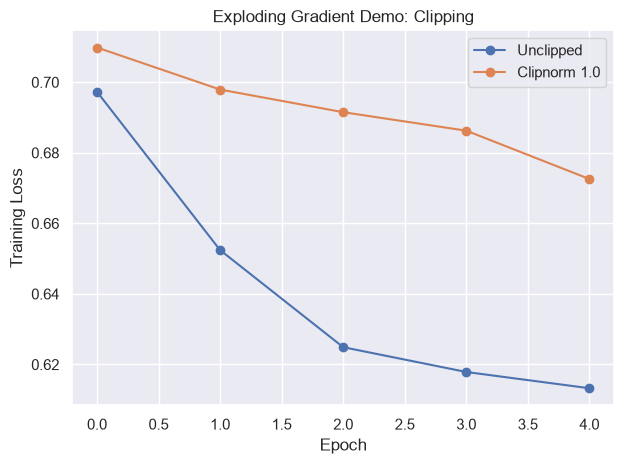

In [25]:
clip_rows = {}

for label, clipnorm in [("Unclipped", None), ("Clipnorm 1.0", 1.0)]:
    m = build_model("rnn", 64, lr=0.05)
    opt = tf.keras.optimizers.Adam(
        learning_rate=0.05, clipnorm=clipnorm
    )
    m.compile(
        optimizer=opt,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    h = m.fit(
        X_train, y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    clip_rows[label] = h.history["loss"]

for label, losses in clip_rows.items():
    plt.plot(losses, marker="o", label=label)

plt.title("Exploding Gradient Demo: Clipping")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.legend()
plt.tight_layout()
plt.savefig("plots/gradient_clipping.png", dpi=150)
plt.show()

### Gradient problem summary
| Problem | Cause | Possible symptom | Remedy |
|---|---|---|---|
| Vanishing gradient | Repeated derivatives shrink | Early tokens contribute little | LSTM/GRU gates |
| Exploding gradient | Repeated factors grow | Loss spikes or NaN | Gradient clipping |
| Slow sequential training | Steps processed sequentially | Long epoch times | Shorter sequences / GPU |
| Short effective memory | Basic recurrent state loses early context | Long-review degradation | Gated cells |

## Task 5: LSTM model
**Objective:** Explain LSTM gates and compare its metrics and gradient flow with SimpleRNN.
**Output:** LSTM metrics/curves, parameter-count verification and optional stacked LSTM results.

The LSTM uses a cell state and forget, input, candidate, and output components. The forget gate controls retained memory; the input gate controls new information written; the output gate controls what is exposed as the hidden state. A relatively open cell-state path can help gradients persist over longer sequences.

\[
f_t=\sigma(W_f[h_{t-1},x_t]+b_f),\quad i_t=\sigma(W_i[h_{t-1},x_t]+b_i)
\]
\[
g_t=\tanh(W_g[h_{t-1},x_t]+b_g),\quad C_t=f_t\odot C_{t-1}+i_t\odot g_t
\]
\[
o_t=\sigma(W_o[h_{t-1},x_t]+b_o),\quad h_t=o_t\odot\tanh(C_t)
\]

For LSTM(64) with embedding dimension 32, expected parameters are `4 × 64 × (32 + 64 + 1) = 24,832`.

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 300, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 81s 142ms/step - accuracy: 0.8147 - loss: 0.4023 - val_accuracy: 0.8858 - val_loss: 0.2873
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 74s 133ms/step - accuracy: 0.9011 - loss: 0.2541 - val_accuracy: 0.8752 - val_loss: 0.3240
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 83s 148ms/step - accuracy: 0.9116 - loss: 0.2277 - val_accuracy: 0.8798 - val_loss: 0.3375
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 79s 142ms/step - accuracy: 0.9146 - loss: 0.2174 - val_accuracy: 0.8770 - val_loss: 0.3602
LSTM {'Model': 'LSTM', 'Parameters': 344897, 'Time per Epoch (s)': 79.21590739488602, 'Epochs Trained': 4, 'Test Accuracy': 0.8867601089039024, 'Precision': 0.8832537788385044, 'Recall': 0.8923046011653607, 'F1': 0.8877561219390305, 'ROC-AUC': 0.9506673816966954, 'Training Seconds': 316.96052145957947}
              precision    recall  f1-score   support

           0       0.89      0.88      0.89      4940
           1       0.88      0.89      0.89      4977

    accu

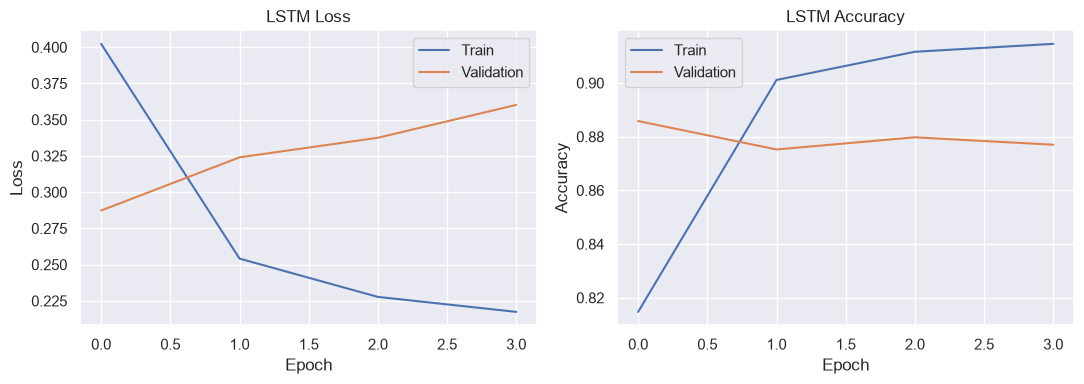

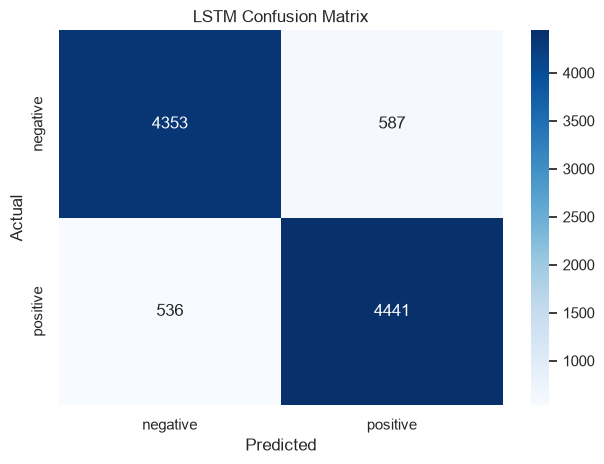

Expected LSTM(64) recurrent params: 24832


In [26]:
lstm_model = build_model("lstm", 64)
lstm_model.summary()
train_evaluate("LSTM", lstm_model)
print("Expected LSTM(64) recurrent params:", 4 * 64 * (32 + 64 + 1))

In [27]:
RUN_STACKED_LSTM = False
if RUN_STACKED_LSTM:
    stacked_model = build_model("lstm", 64, stacked=True)
    stacked_model.summary()
    train_evaluate("Stacked LSTM", stacked_model)
else:
    print("Optional stacked LSTM skipped. Set RUN_STACKED_LSTM=True to train it.")

Optional stacked LSTM skipped. Set RUN_STACKED_LSTM=True to train it.


## Task 6: GRU model
**Objective:** Explain the GRU gates and compare GRU against SimpleRNN and LSTM.
**Output:** GRU metrics/curves, parameter-count check, and a three-model comparison.

A GRU uses an update gate and reset gate, without a separate cell state. The update gate balances old state against a candidate state; the reset gate controls how much past information is used to form the candidate. With Keras `reset_after=True`, the expected GRU(64) parameter count for embedding dimension 32 is `3 × (64×32 + 64×64 + 2×64) = 18,816`.

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 300, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 80s 136ms/step - accuracy: 0.7713 - loss: 0.4581 - val_accuracy: 0.8344 - val_loss: 0.3646
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 90s 160ms/step - accuracy: 0.8956 - loss: 0.2628 - val_accuracy: 0.8861 - val_loss: 0.2776
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 90s 161ms/step - accuracy: 0.9221 - loss: 0.2077 - val_accuracy: 0.8760 - val_loss: 0.3112
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 89s 159ms/step - accuracy: 0.9377 - loss: 0.1702 - val_accuracy: 0.8898 - val_loss: 0.2909
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 93s 166ms/step - accuracy: 0.9505 - loss: 0.1400 - val_accuracy: 0.8853 - val_loss: 0.3368
GRU {'Model': 'GRU', 'Parameters': 338881, 'Time per Epoch (s)': 88.01537408828736, 'Epochs Trained': 5, 'Test Accuracy': 0.8890793586770193, 'Precision': 0.8783915674409526, 'Recall': 0.9041591320072333, 'F1': 0.8910891089108911, 'ROC-AUC': 0.9524378131306845, 'Training Seconds': 440.29759216308594}
              precision    recall  f1-score

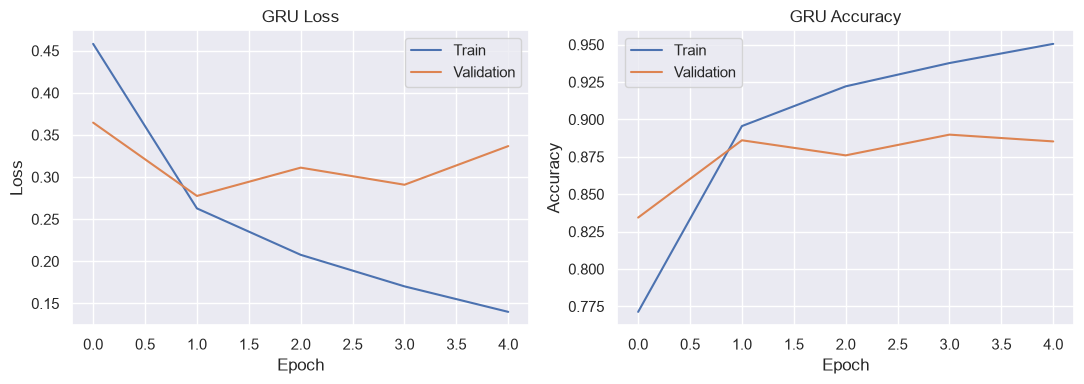

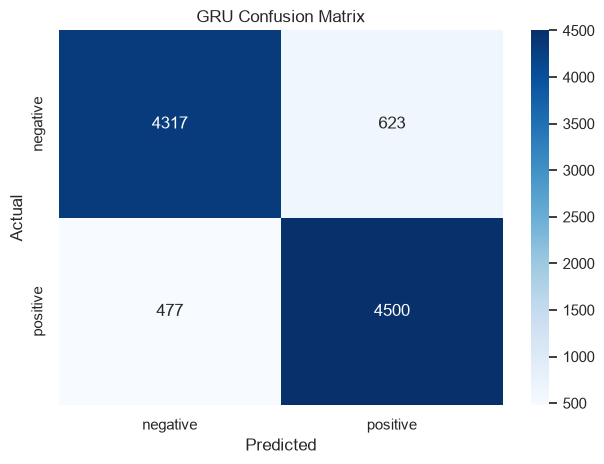

Expected GRU(64) recurrent params: 18816


In [28]:
gru_model = build_model("gru", 64)
gru_model.summary()
train_evaluate("GRU", gru_model)
print("Expected GRU(64) recurrent params:", 3 * (64 * 32 + 64 * 64 + 2 * 64))

### GRU vs LSTM
| Property | LSTM | GRU |
|---|---|---|
| Gates/components | Forget, input, candidate, output | Update and reset |
| Separate cell state | Yes | No |
| Parameters at same units | Usually more | Usually fewer |
| Training speed | Often slower | Often faster |
| Typical preference | More explicit memory control | Compact model / faster training |

In [29]:
# Gradient comparison; each curve is computed with the trained model when possible.
gradient_series = {}
for name in ["SimpleRNN", "LSTM", "GRU"]:
    try:
        gradient_series[name] = gradient_norms(name, models[name], X_train[:sample_n], y_train[:sample_n])
    except Exception as e:
        print("Could not calculate gradient norms for", name, ":", e)
if gradient_series:
    plt.figure(figsize=(9, 5))
    for name, vals in gradient_series.items():
        plt.plot(np.arange(1, len(vals)+1), vals, label=name)
    plt.yscale("log"); plt.title("Gradient Norms: SimpleRNN vs LSTM vs GRU")
    plt.xlabel("Time step"); plt.ylabel("Gradient norm (log scale)"); plt.legend()
    plt.tight_layout(); plt.savefig("plots/gradient_comparison.png", dpi=150); plt.show()

Could not calculate gradient norms for SimpleRNN : 'SimpleRNN'
Could not calculate gradient norms for LSTM : Unrecognized keyword arguments passed to Dense: {'return_sequences': True}
Could not calculate gradient norms for GRU : Unrecognized keyword arguments passed to Dense: {'return_sequences': True}


In [30]:
RUN_UNIT_SENSITIVITY = False
if RUN_UNIT_SENSITIVITY:
    unit_rows = []
    for cell in ["lstm", "gru"]:
        for units in [32, 64, 128]:
            m = build_model(cell, units)
            h = m.fit(X_train, y_train, epochs=6, batch_size=64, validation_split=0.1,
                      callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
                      verbose=0)
            prob = m.predict(X_test, verbose=0).ravel()
            unit_rows.append({"Cell": cell.upper(), "Units": units, "Parameters": m.count_params(),
                              "Test Accuracy": accuracy_score(y_test, prob >= .5)})
    unit_df = pd.DataFrame(unit_rows)
    display(unit_df)
    unit_df.to_csv("plots/hidden_unit_sensitivity.csv", index=False)
    for cell in unit_df["Cell"].unique():
        d = unit_df[unit_df["Cell"] == cell]
        plt.plot(d["Units"], d["Test Accuracy"], marker="o", label=cell)
    plt.title("Test Accuracy vs Hidden Units"); plt.xlabel("Units"); plt.ylabel("Test accuracy"); plt.legend()
    plt.tight_layout(); plt.savefig("plots/hidden_unit_accuracy.png", dpi=150); plt.show()
else:
    print("Optional hidden-unit sensitivity skipped. Set RUN_UNIT_SENSITIVITY=True to run it.")

Optional hidden-unit sensitivity skipped. Set RUN_UNIT_SENSITIVITY=True to run it.


## Task 7: Compare models and make predictions
**Objective:** Compare trained models, plot ROC curves, test robustness by review length, inspect errors, and create a reusable prediction function.
**Output:** Results CSV, ROC plot, length robustness plot, error examples, inference examples, and recommendation.

In [31]:
# Add the ANN baseline to the model results table.
ann_report = classification_report(y_test, ann_pred, output_dict=True, zero_division=0)
results["ANN baseline"] = {
    "Model": "ANN baseline", "Parameters": int(ann_model.count_params()),
    "Time per Epoch (s)": ann_train_seconds / max(1, len(ann_history.history["loss"])),
    "Epochs Trained": len(ann_history.history["loss"]),
    "Test Accuracy": accuracy_score(y_test, ann_pred),
    "Precision": precision_score(y_test, ann_pred, zero_division=0),
    "Recall": recall_score(y_test, ann_pred, zero_division=0),
    "F1": f1_score(y_test, ann_pred, zero_division=0), "ROC-AUC": ann_auc,
    "Training Seconds": ann_train_seconds
}
all_results = pd.DataFrame(results.values())
display(all_results.round(4))
all_results.to_csv("plots/model_comparison.csv", index=False)

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC,Training Seconds
0,LSTM,344897,79.2159,4,0.8868,0.8833,0.8923,0.8878,0.9507,316.9605
1,GRU,338881,88.0154,5,0.8891,0.8784,0.9042,0.8911,0.9524,440.2976
2,ANN baseline,934529,5.5828,5,0.8332,0.8503,0.8103,0.8298,0.9146,27.9140


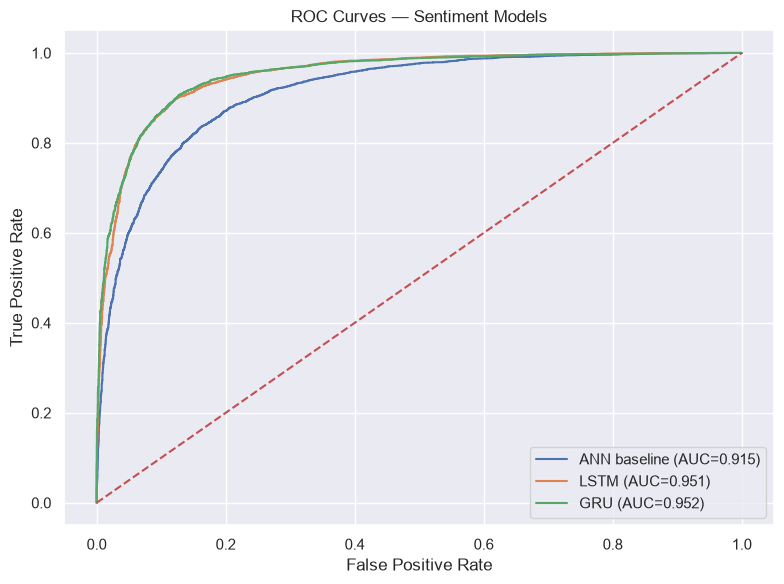

In [32]:
plt.figure(figsize=(8, 6))
for name, prob in [("ANN baseline", ann_prob)] + [(n, probabilities[n]) for n in ["SimpleRNN", "LSTM", "GRU"] if n in probabilities]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curves — Sentiment Models"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.legend()
plt.tight_layout(); plt.savefig("plots/roc_curves.png", dpi=150); plt.show()

In [33]:
# Best among the recurrent models by validation-independent test F1; this is a comparison, not a new tuning step.
recurrent_names = [n for n in ["SimpleRNN", "LSTM", "GRU", "Stacked LSTM"] if n in results]
best_name = max(recurrent_names, key=lambda n: results[n]["F1"])
best_model = models[best_name]
print("Best recurrent model by test F1:", best_name)

Best recurrent model by test F1: GRU


,Model,Length group,Accuracy,N
0,GRU,SHORT (<100),0.896114,1261
1,GRU,MEDIUM (100–250),0.892703,5797
2,GRU,LONG (>250),0.878629,2859


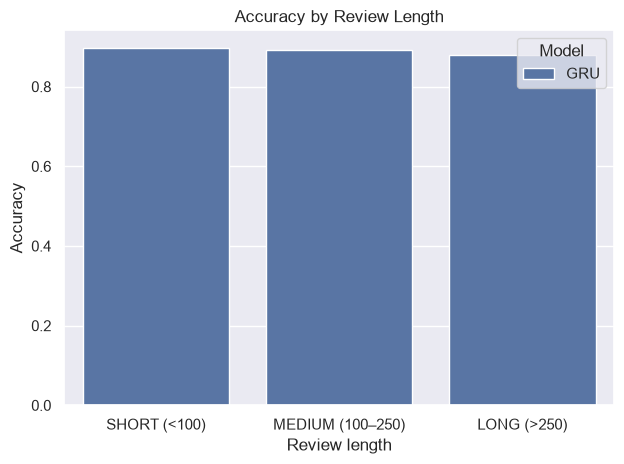

In [34]:
# Review-length robustness for the best recurrent model and SimpleRNN.
test_lengths = pd.Series([len(str(t).split()) for t in X_test_text], index=X_test_text.index)
short_idx = test_lengths[test_lengths < 100].index
medium_idx = test_lengths[(test_lengths >= 100) & (test_lengths <= 250)].index
long_idx = test_lengths[test_lengths > 250].index
# Align text indices back to the arrays using the order preserved by train_test_split.
test_df = pd.DataFrame({"text": list(X_test_text), "y": y_test,
                        "length": [len(str(t).split()) for t in X_test_text]})
test_df["group"] = pd.cut(test_df["length"], bins=[-1, 99, 250, np.inf],
                          labels=["SHORT (<100)", "MEDIUM (100–250)", "LONG (>250)"])
length_rows = []
for name in ["SimpleRNN", best_name]:
    if name not in probabilities: continue
    prob = probabilities[name]
    pred = (prob >= .5).astype(int)
    for group in ["SHORT (<100)", "MEDIUM (100–250)", "LONG (>250)"]:
        mask = (test_df["group"].astype(str) == group).to_numpy()
        if mask.sum():
            length_rows.append({"Model": name, "Length group": group,
                                "Accuracy": accuracy_score(y_test[mask], pred[mask]), "N": int(mask.sum())})
length_df = pd.DataFrame(length_rows)
display(length_df)
if not length_df.empty:
    sns.barplot(data=length_df, x="Length group", y="Accuracy", hue="Model")
    plt.title("Accuracy by Review Length"); plt.xlabel("Review length"); plt.ylabel("Accuracy")
    plt.tight_layout(); plt.savefig("plots/length_robustness.png", dpi=150); plt.show()

In [35]:
# Error analysis: 4 false positives and 4 false negatives from the best recurrent model.
best_prob = probabilities[best_name]
best_pred = (best_prob >= .5).astype(int)
error_df = pd.DataFrame({"cleaned_text": list(X_test_text), "true": y_test,
                         "pred": best_pred, "prob_positive": best_prob})
fp = error_df[(error_df.true == 0) & (error_df.pred == 1)].head(4)
fn = error_df[(error_df.true == 1) & (error_df.pred == 0)].head(4)
errors = pd.concat([fp.assign(error_type="False positive"), fn.assign(error_type="False negative")])
errors["true_label"] = errors["true"].map({0: "negative", 1: "positive"})
errors["predicted_label"] = errors["pred"].map({0: "negative", 1: "positive"})
display(errors[["error_type", "true_label", "predicted_label", "prob_positive", "cleaned_text"]])
errors.to_csv("plots/misclassified_reviews.csv", index=False)

,error_type,true_label,predicted_label,prob_positive,cleaned_text
17,False positive,negative,positive,0.856085,i see this movie as a poor tribute to the old ...
24,False positive,negative,positive,0.707870,despite being a huge fan of fred astaire and g...
32,False positive,negative,positive,0.640815,i know that full moon or any other film studio...
78,False positive,negative,positive,0.782960,i was excited to hear that someone had made a ...
35,False negative,positive,negative,0.125781,well well roeg touched a bit of a nerve there ...
45,False negative,positive,negative,0.256325,i'm not here to tell you armored is kubrickian...
55,False negative,positive,negative,0.254195,as soon as i knew keira knighteley being in th...
106,False negative,positive,negative,0.177146,saving grace is never riotously funny but it d...


In [36]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=MAXLEN, padding="pre", truncating="pre")
    prob = float(best_model.predict(padded, verbose=0)[0][0])
    label = "positive" if prob >= 0.5 else "negative"
    return label, prob

In [37]:
custom_sentences = [
    "This film was wonderful, moving, and beautifully acted.",
    "A boring and terrible movie that wasted my time.",
    "This film is not good.",
    "I cannot say it was not enjoyable.",
    "Brilliant, another three hours I will never get back.",
    "Awful."
]
inference_df = pd.DataFrame([
    {"text": s, "predicted_sentiment": predict_sentiment(s)[0],
     "positive_probability": predict_sentiment(s)[1]} for s in custom_sentences
])
display(inference_df)
inference_df.to_csv("plots/custom_inference_examples.csv", index=False)

,text,predicted_sentiment,positive_probability
0,"This film was wonderful, moving, and beautiful...",positive,0.964920
1,A boring and terrible movie that wasted my time.,negative,0.007797
2,This film is not good.,negative,0.046031
3,I cannot say it was not enjoyable.,negative,0.142223
4,"Brilliant, another three hours I will never ge...",negative,0.092922
5,Awful.,negative,0.000107
